In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, RocCurveDisplay

df = pd.read_csv("employee_turnover.csv")
df = df.drop_duplicates()

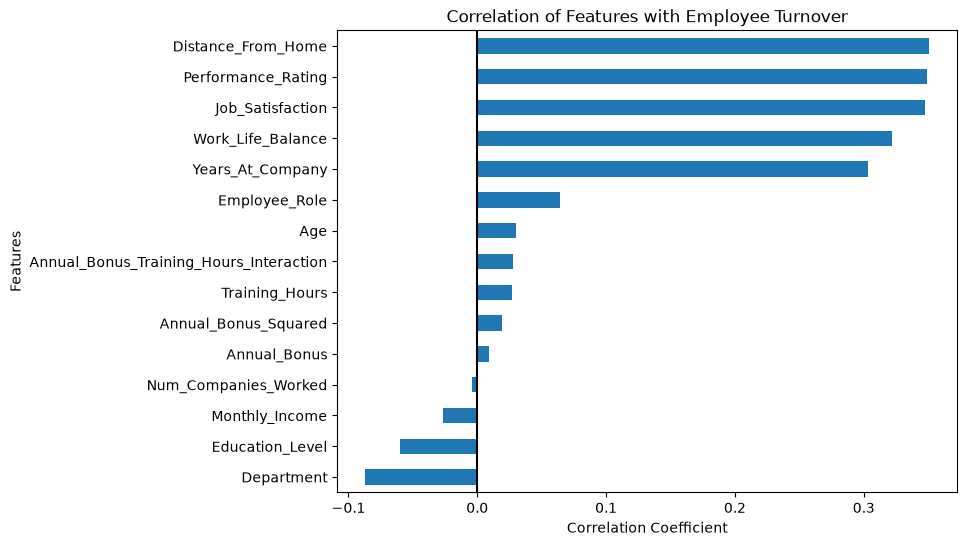

In [2]:
df["Employee_Turnover"].value_counts(normalize = True)
target_corr = df.corr()["Employee_Turnover"].drop("Employee_Turnover").sort_values()
plt.figure(figsize=(8, 6))
target_corr.plot(kind="barh")
plt.axvline(0, color = "black")
plt.title("Correlation of Features with Employee Turnover")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Features")
plt.show()

<Figure size 1000x800 with 0 Axes>

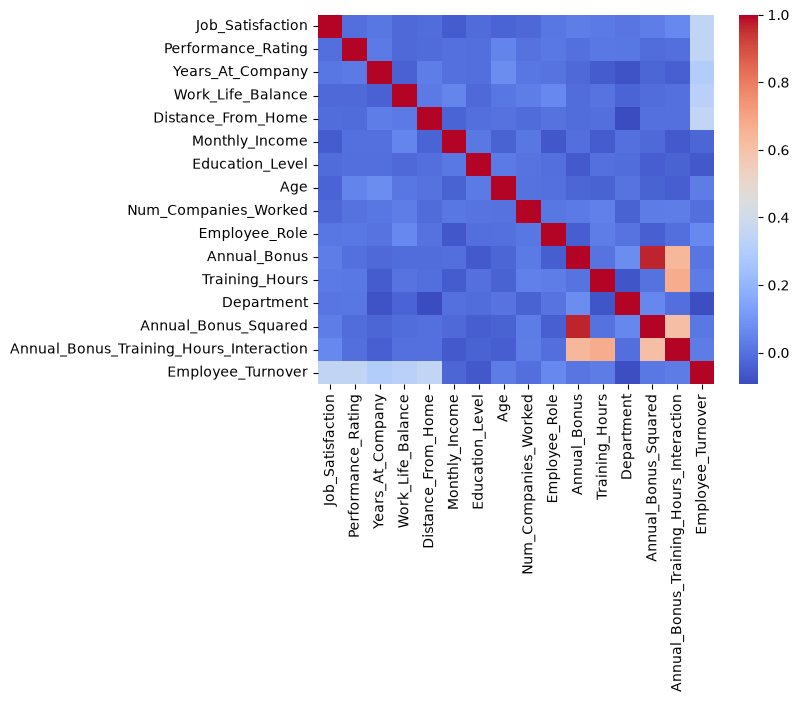

<Figure size 1000x800 with 0 Axes>

In [3]:
sns.heatmap(df.corr(), cmap = "coolwarm")
plt.figure(figsize=(10, 8))


In [4]:
#training model
X = df.drop("Employee_Turnover", axis = 1)
y = df["Employee_Turnover"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)



In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
baseline = LogisticRegression(C=np.inf, max_iter = 1000)
baseline.fit(X_train_scaled, y_train)
y_pred = baseline.predict(X_test_scaled)
y_prob = baseline.predict_proba(X_test_scaled)[:, 1]

In [7]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC AUC Score:", roc_auc_score(y_test, y_prob))

Accuracy: 0.85
Precision: 0.9113924050632911
Recall: 0.782608695652174
F1 Score: 0.8421052631578947
ROC AUC Score: 0.9504693675889327


In [8]:
from sklearn.model_selection import GridSearchCV

In [9]:
param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100]}
base = LogisticRegression(l1_ratio=0, max_iter=5000)
grid_search = GridSearchCV(base, param_grid, cv=5, scoring='roc_auc')
grid_search.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...max_iter=5000)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with

In [10]:
print(best_params := grid_search.best_params_)
model = grid_search.best_estimator_
y_pred_l2 = model.predict(X_test_scaled)
y_prob_l2 = model.predict_proba(X_test_scaled)[:, 1]

{'C': 1}


In [11]:
print("Accuracy:", accuracy_score(y_test, y_pred_l2))
print("Precision:", precision_score(y_test, y_pred_l2))
print("Recall:", recall_score(y_test, y_pred_l2))
print("F1 Score:", f1_score(y_test, y_pred_l2))
print("ROC AUC Score:", roc_auc_score(y_test, y_prob_l2))

Accuracy: 0.8444444444444444
Precision: 0.9102564102564102
Recall: 0.7717391304347826
F1 Score: 0.8352941176470589
ROC AUC Score: 0.9508399209486166


In [12]:
param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100]}
base_l1 = LogisticRegression(l1_ratio=1, solver='liblinear', max_iter=5000)
grid_search_l1 = GridSearchCV(base_l1, param_grid, cv=5, scoring='roc_auc')
grid_search_l1.fit(X_train_scaled, y_train)

print(best_params_l1 := grid_search_l1.best_params_)
model_l1 = grid_search_l1.best_estimator_
y_pred_l1 = model_l1.predict(X_test_scaled)
y_prob_l1 = model_l1.predict_proba(X_test_scaled)[:, 1]

{'C': 0.1}


In [13]:
print("Accuracy:", accuracy_score(y_test, y_pred_l1))
print("Precision:", precision_score(y_test, y_pred_l1))
print("Recall:", recall_score(y_test, y_pred_l1))
print("F1 Score:", f1_score(y_test, y_pred_l1))
print("ROC AUC Score:", roc_auc_score(y_test, y_prob_l1))

Accuracy: 0.85
Precision: 0.9113924050632911
Recall: 0.782608695652174
F1 Score: 0.8421052631578947
ROC AUC Score: 0.9575098814229249


In [14]:
coef_l1 = pd.Series(model_l1.coef_[0], index=X.columns)
print("Coefficients (L1 Regularization):")
print(coef_l1.sort_values())

coef_l2 = pd.Series(model.coef_[0], index=X.columns)
print("Coefficients (L2 Regularization):")
print(coef_l2.sort_values())

coef_baseline = pd.Series(baseline.coef_[0], index=X.columns)
print("Coefficients (Baseline Model):")
print(coef_baseline.sort_values())

Coefficients (L1 Regularization):
Education_Level                           -0.076624
Department                                -0.025382
Monthly_Income                             0.000000
Age                                        0.000000
Num_Companies_Worked                       0.000000
Annual_Bonus                               0.000000
Training_Hours                             0.000000
Annual_Bonus_Squared                       0.000000
Annual_Bonus_Training_Hours_Interaction    0.000000
Employee_Role                              0.057770
Years_At_Company                           1.076285
Distance_From_Home                         1.211116
Job_Satisfaction                           1.212040
Work_Life_Balance                          1.229606
Performance_Rating                         1.299317
dtype: float64
Coefficients (L2 Regularization):
Annual_Bonus                              -0.305150
Education_Level                           -0.229123
Age                              

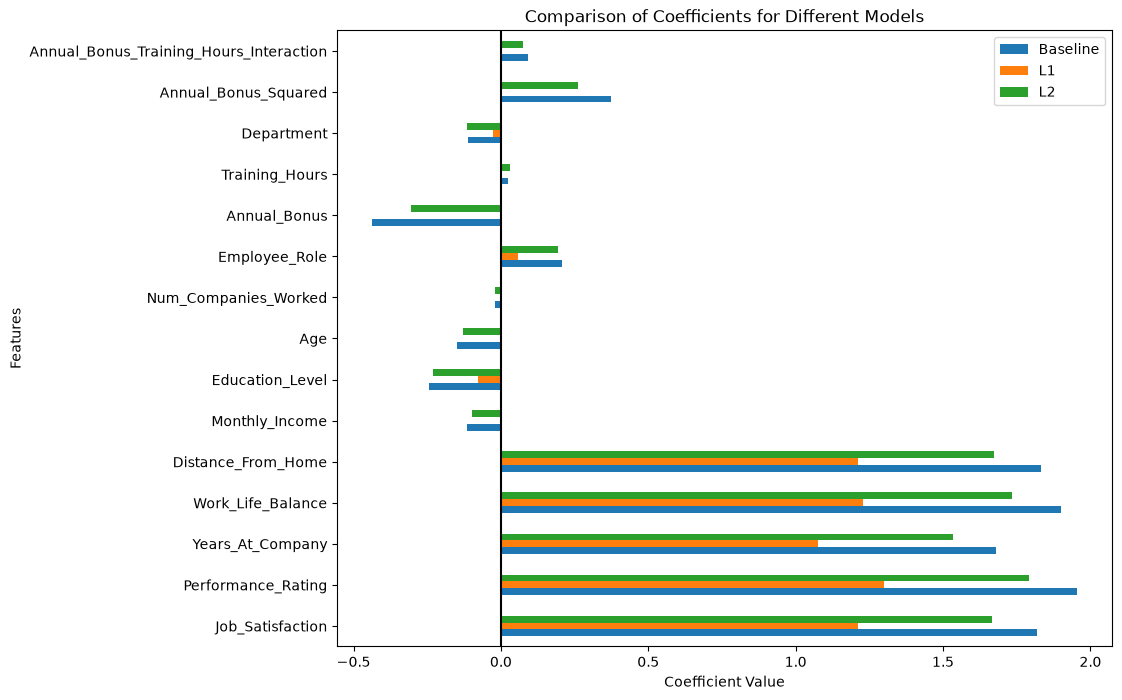

In [15]:
pd.DataFrame({"Baseline": coef_baseline, "L1": coef_l1, "L2": coef_l2}).plot(kind='barh', figsize=(10, 8))
plt.axvline(0, color='black')
plt.title("Comparison of Coefficients for Different Models")
plt.xlabel("Coefficient Value")
plt.ylabel("Features")
plt.show()

In [16]:
results = pd.DataFrame({
    'Model':    ['Baseline', 'L1', 'L2'],
    'Accuracy': [accuracy_score(y_test, y_pred),
                 accuracy_score(y_test, y_pred_l1),
                 accuracy_score(y_test, y_pred_l2)],
    'Precision': [precision_score(y_test, y_pred),
                  precision_score(y_test, y_pred_l1),
                  precision_score(y_test, y_pred_l2)],
    'Recall': [recall_score(y_test, y_pred),
                recall_score(y_test, y_pred_l1),
                recall_score(y_test, y_pred_l2)],   
    "F1_score": [f1_score(y_test, y_pred),
                f1_score(y_test, y_pred_l1),
                f1_score(y_test, y_pred_l2)],
    "ROC_AUC_Score": [roc_auc_score(y_test, y_prob),
                      roc_auc_score(y_test, y_prob_l1),
                      roc_auc_score(y_test, y_prob_l2)],
    'Features used': [15, (model_l1.coef_[0] != 0).sum(), 15]
})

results.round(3)

,Model,Accuracy,Precision,Recall,F1_score,ROC_AUC_Score,Features used
0,Baseline,0.850,0.911,0.783,0.842,0.950,15
1,L1,0.850,0.911,0.783,0.842,0.958,8
2,L2,0.844,0.910,0.772,0.835,0.951,15


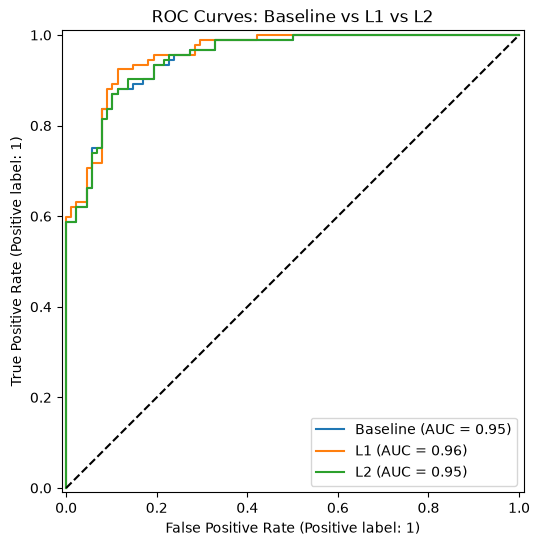

In [17]:
from sklearn.metrics import RocCurveDisplay
fig, ax = plt.subplots(figsize=(7, 6))

RocCurveDisplay.from_estimator(baseline, X_test_scaled, y_test, ax=ax, name='Baseline')
RocCurveDisplay.from_estimator(model_l1, X_test_scaled, y_test, ax=ax, name='L1')
RocCurveDisplay.from_estimator(model, X_test_scaled, y_test, ax=ax, name='L2')
ax.plot([0, 1], [0, 1], 'k--')
ax.set_title('ROC Curves: Baseline vs L1 vs L2')
plt.show()

Model Comparison

All three models performed similarly:

Baseline: accuracy 0.850, AUC 0.951, 15 features
L1 (C = 0.1): accuracy 0.850, AUC 0.958, 8 features
L2 (C = 1): accuracy 0.844, AUC 0.951, 15 features

The baseline was not overfitting, so regularization did not raise accuracy. The differences between models are 1 employee or less out of 180.

Recommended Model: L1 (Lasso) Logistic Regression
Same accuracy as the baseline, best AUC (0.958).
Simpler: it uses 8 features instead of 15. It removed income, age, bonus, training hours, number of previous companies and the two engineered bonus features.
Matches the EDA: the 5 features it relies on are the same ones that had the strongest correlation with turnover.
Handles multicollinearity: the baseline gave Annual_Bonus and Annual_Bonus_Squared large, opposite coefficients. L1 removed both.
Easier for HR to act on: 5 clear drivers instead of 15.

Limitation: recall is 0.78, so the model misses about 1 in 5 employees who leave. Lowering the decision threshold below 0.5 would catch more leavers, at the cost of more false alarms.

Business Insights for HR

Main drivers of turnover (from strongest):

Performance_Rating
Work_Life_Balance
Job_Satisfaction
Distance_From_Home
Years_At_Company

Suggested actions:

Distance from home: offer remote or hybrid work, or transport support.
Work-life balance: review workloads and offer flexible hours.
High performers: strong performers are more likely to leave, possibly because other companies recruit them. Review their pay, growth paths and recognition.
Tenure: hold check-ins at key work anniversaries.

No measurable effect: salary, bonus and training hours. Raising pay alone may not reduce turnover.

Data note: higher Job_Satisfaction and Work_Life_Balance scores were linked to more turnover, which is counterintuitive. The dataset may be synthetic, or these columns may be encoded in reverse. Results should be confirmed on real company data.